# Chapter 6 notebook: trust a wave calculation

**Predict first:** can a conservative system solve the wrong wave accurately?
We solve a one-dimensional normal-incidence dielectric slab by FDFD and compare it with the independent Chapter 2 Fresnel film. The convention is $e^{-i\omega t}$; incident $E_y=1$ at $z=0$, reflected amplitude at $z=0$, transmitted amplitude at $z=d$. Equal real exterior indices, isotropic nonmagnetic materials, micrometers. No PML, FDTD, FEM, finite ridge array, material dispersion, or experiment is executed here.

Restart the kernel and run all cells. Preserve the complete source bundle. Plot labels remain common scientific English in both editions; Persian narratives describe their meaning.

In [1]:
# Parameters: physical experiment and numerical controls are separate.
from dataclasses import asdict
from pathlib import Path
import hashlib, json, platform, sys
import numpy as np
import scipy
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import HTML, display

ROOT = Path.cwd()
if not (ROOT / 'simulations').is_dir(): ROOT = ROOT.parent
assert (ROOT / 'simulations/numerical_methods.py').is_file(), 'Extract the complete source bundle.'
sys.path.insert(0, str(ROOT / 'simulations'))
from numerical_methods import Slab, solve_slab, exact_slab, exact_slab_fields, phase_error_deg, summarize_result

SLAB = Slab(wavelength_um=1.55, thickness_um=0.60, n_film=2.4, n_exterior=1.0)
MESH_CELLS = [4, 8, 16, 32, 64, 128, 256, 512]
FIELD_CELLS = [8, 64, 512]
PADDING_MESH = 8
PADDING_CELLS = list(range(65))
AMPLITUDE_TARGET = 1e-3
PHASE_TARGET_DEG = 0.1
PHASE_AMPLITUDE_FLOOR = 1e-8

plt.rcParams.update({'figure.dpi': 130, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .22})
COLORS = ['#156a91', '#c05a23', '#25734f']
reference = exact_slab(SLAB)
print('Physical parameters:', asdict(SLAB))
print('Python / NumPy / SciPy / Matplotlib:', platform.python_version(), np.__version__, scipy.__version__, matplotlib.__version__)
print('Source SHA256:', hashlib.sha256((ROOT/'simulations/numerical_methods.py').read_bytes()).hexdigest())
print('Exact r, t, R, T:', reference['r'], reference['t'], reference['R'], reference['T'])

Physical parameters: {'wavelength_um': 1.55, 'thickness_um': 0.6, 'n_film': 2.4, 'n_exterior': 1.0}
Python / NumPy / SciPy / Matplotlib: 3.12.1 2.4.6 1.18.1 3.11.1
Source SHA256: 24f0cc7c187c6c92ba906aea101024b3249be87a2bae86c9ad148c79e7c0dd51
Exact r, t, R, T: (-0.2195960689010276-0.3261968489579452j) (0.7627137674043337-0.5134597270137267j) 0.15462681774687742 0.8453731822531227


## 1. Separate three diagnostics

Compute complex transmission error, the normalized equation residual, and discrete flux imbalance independently. The exact solution is used to judge the numerical prediction; it is not used to assemble the FDFD equations. Predict whether power imbalance will decrease at the same rate as transmission error.

Logarithmic diagnostics at zero or below 1e-17 are displayed at a plotting floor of 1e-17; this floor is not a measured error.

In [2]:
solutions = [solve_slab(SLAB, cells=n) for n in MESH_CELLS]
mesh = [summarize_result(s, reference) for s in solutions]
rows = ''.join(f"<tr><td>{r['cells']}</td><td>{r['complex_t_error']:.4g}</td><td>{r['phase_error_deg']:.5g}</td><td>{r['energy_defect']:.2e}</td><td>{r['algebraic_residual']:.2e}</td></tr>" for r in mesh)
display(HTML('<table><tr><th>Film cells N</th><th>|t - exact|</th><th>Phase error (deg)</th><th>Flux defect</th><th>Equation residual</th></tr>'+rows+'</table>'))
accepted = [r for r in mesh if r['complex_t_error'] < AMPLITUDE_TARGET and abs(r['phase_error_deg']) < PHASE_TARGET_DEG and abs(reference['t']) > PHASE_AMPLITUDE_FLOOR]
print('First sampled mesh meeting BOTH targets:', accepted[0]['cells'] if accepted else 'None: refine further')
for a,b in zip(mesh[-4:-1], mesh[-3:]):
    print(f"N {a['cells']} -> {b['cells']}: exact-error observed order {np.log2(a['complex_t_error']/b['complex_t_error']):.5f}")
assert max(r['algebraic_residual'] for r in mesh) < 1e-9
assert max(r['energy_defect'] for r in mesh) < 1e-9

Film cells N,|t - exact|,Phase error (deg),Flux defect,Equation residual
4,0.8234,50.943,3.33e-16,2.88e-16
8,0.1809,10.684,4.44e-16,5.16e-16
16,0.04243,2.5168,7.77e-16,1.17e-15
32,0.01043,0.61953,2.55e-15,4.81e-15
64,0.002595,0.15428,1.67e-15,1.03e-14
128,0.000648,0.038532,6.66e-16,3.10e-14
256,0.000162,0.0096307,1.11e-15,9.54e-14
512,4.049e-05,0.0024075,3.66e-15,2.98e-13


First sampled mesh meeting BOTH targets: 128
N 64 -> 128: exact-error observed order 2.00159
N 128 -> 256: exact-error observed order 2.00040
N 256 -> 512: exact-error observed order 2.00010


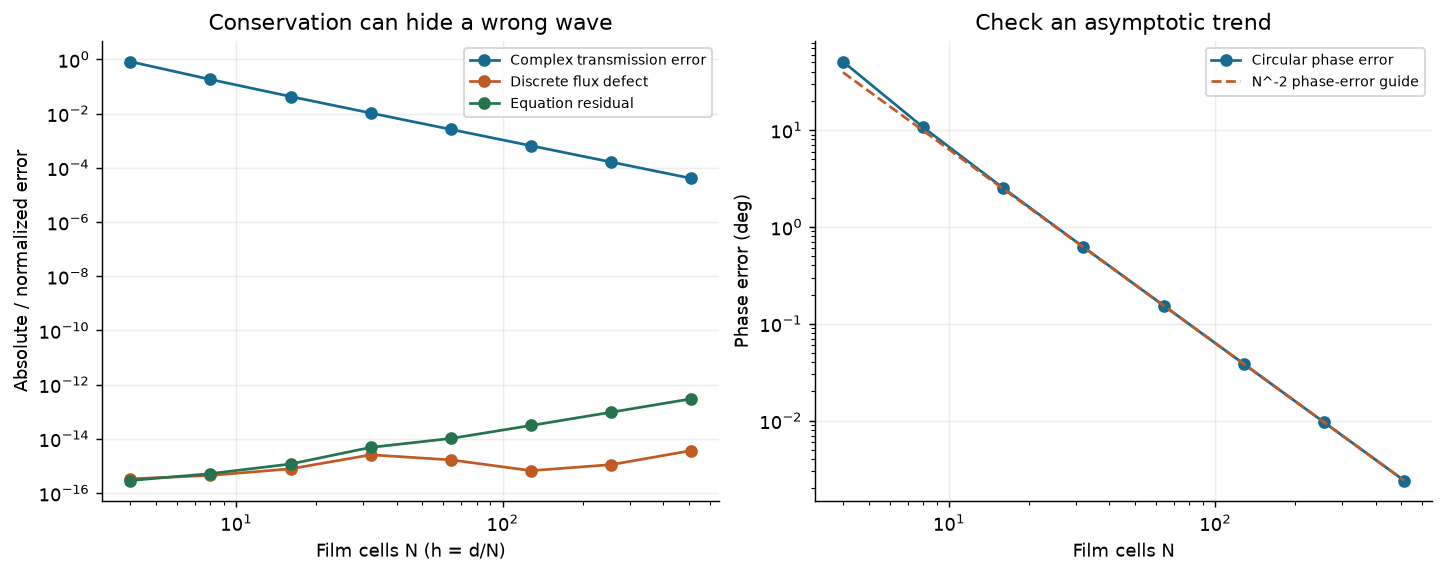

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4.3), layout='constrained')
N = np.array(MESH_CELLS)
for key,label,color in [('complex_t_error','Complex transmission error',COLORS[0]), ('energy_defect','Discrete flux defect',COLORS[1]), ('algebraic_residual','Equation residual',COLORS[2])]:
    ax[0].loglog(N, np.maximum([r[key] for r in mesh], 1e-17), 'o-', color=color, label=label)
ax[0].set(xlabel='Film cells N (h = d/N)', ylabel='Absolute / normalized error', title='Conservation can hide a wrong wave')
ax[0].legend(fontsize=8)
ax[1].loglog(N, np.abs([r['phase_error_deg'] for r in mesh]), 'o-', color=COLORS[0], label='Circular phase error')
ax[1].loglog(N, abs(mesh[-1]['phase_error_deg'])*(N[-1]/N)**2, '--', color=COLORS[1], label='N^-2 phase-error guide')
ax[1].set(xlabel='Film cells N', ylabel='Phase error (deg)', title='Check an asymptotic trend')
ax[1].legend(fontsize=8)
plt.show()

## 2. Compare fields at the same coordinates

The two physical faces remain on nodes. Each face uses the arithmetic half-cell permittivity for this tangential scalar field only. Exterior padding is one-quarter of the slab thickness on each side. Plot the real field and its complex pointwise error; a similar-looking intensity pattern is a weaker test than complex-field agreement.

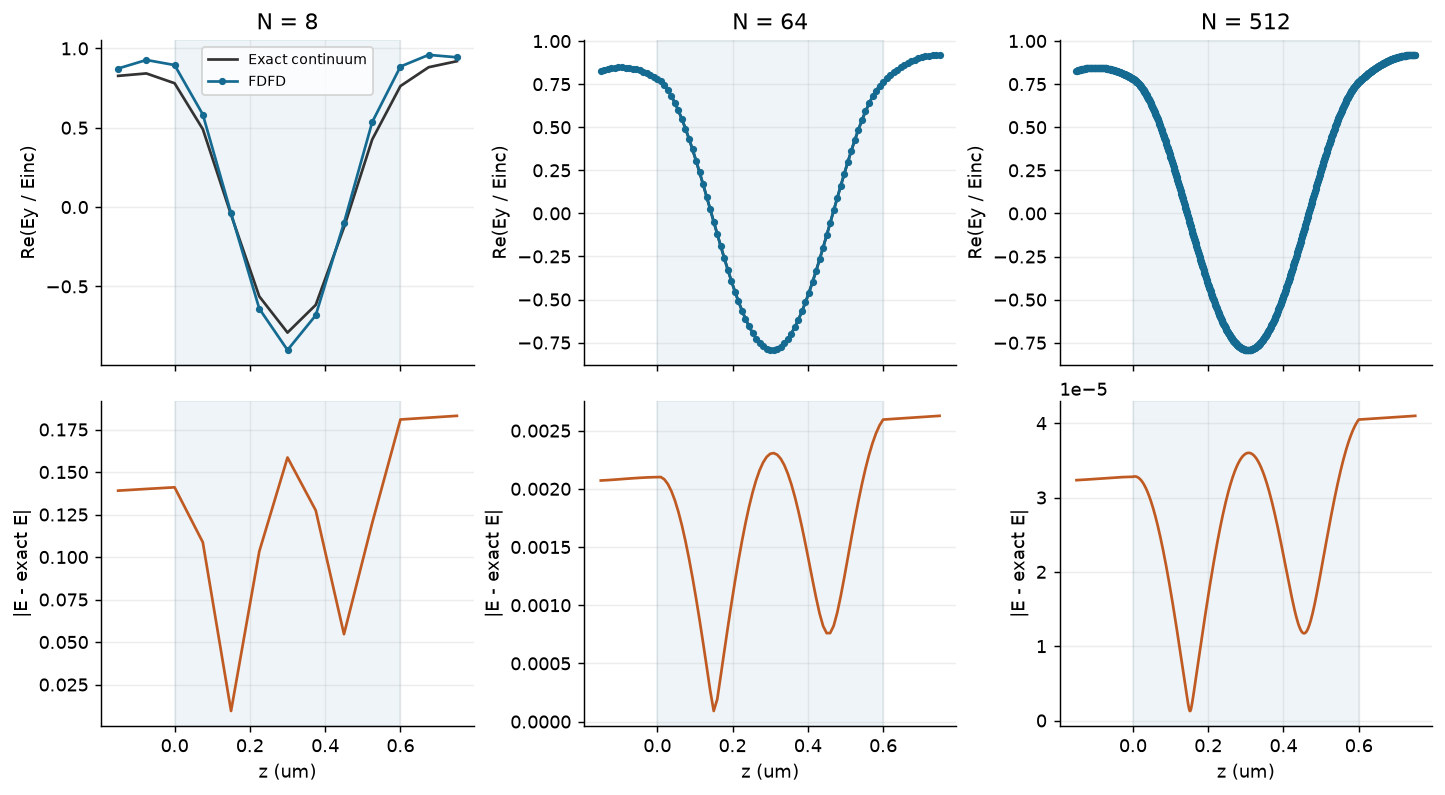

In [4]:
fig, axes = plt.subplots(2, len(FIELD_CELLS), squeeze=False, figsize=(11, 6), sharex='col', layout='constrained')
for col,n in enumerate(FIELD_CELLS):
    s = solve_slab(SLAB, cells=n, left_padding_cells=n//4, right_padding_cells=n//4)
    z, E = s['z_um'], s['E']
    exact_E = exact_slab_fields(SLAB, z)
    axes[0,col].plot(z, exact_E.real, color='0.2', label='Exact continuum')
    axes[0,col].plot(z, E.real, '.-', color=COLORS[0], label='FDFD')
    axes[0,col].set(title=f'N = {n}', ylabel='Re(Ey / Einc)')
    axes[1,col].plot(z, abs(E-exact_E), color=COLORS[1])
    axes[1,col].set(xlabel='z (um)', ylabel='|E - exact E|')
    for a in axes[:,col]: a.axvspan(0, SLAB.thickness_um, color=COLORS[0], alpha=.07)
axes[0,0].legend(fontsize=8)
plt.show()

## 3. Move the boundary; hold the film mesh fixed

Test three distinct changes: matched boundaries with correct deembedding; a deliberately wrong right outgoing multiplier; correct boundaries with continuum deembedding. Forward minus backward power gives net transmitted flux. The mismatched boundary is a controlled error demonstration, not an alternative validated absorber.

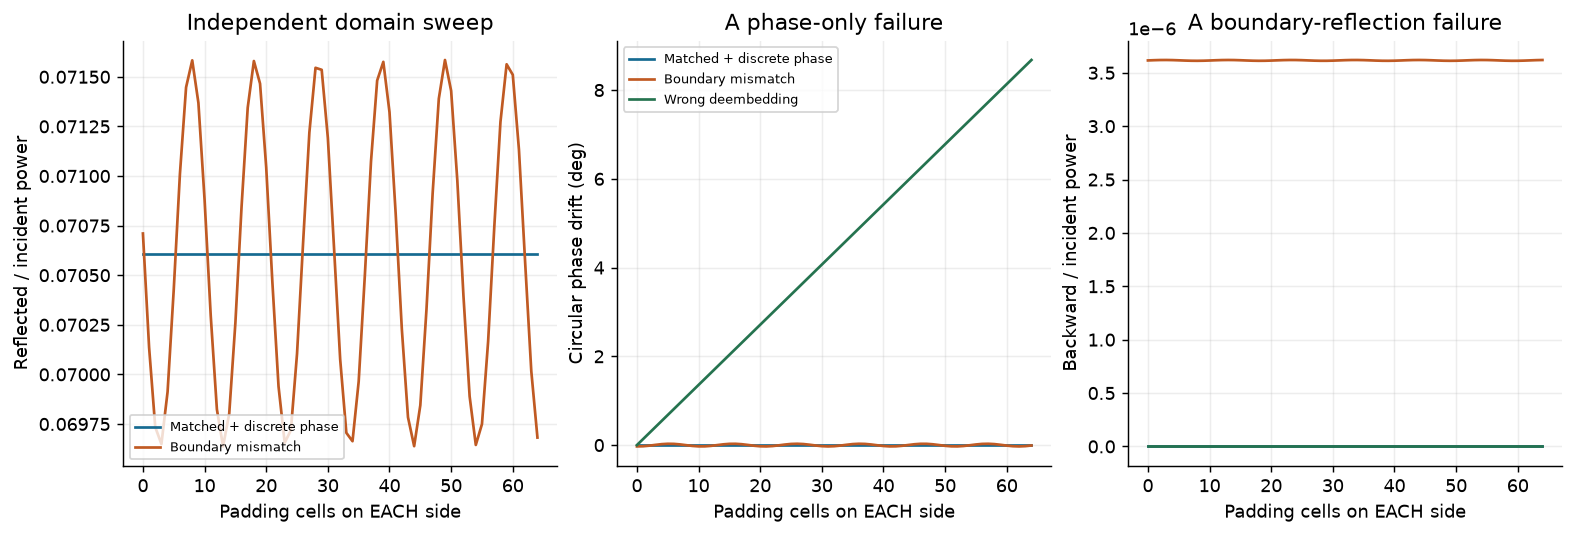

In [5]:
baseline = solve_slab(SLAB, cells=PADDING_MESH)
padding = []
cases = [('discrete','discrete','Matched + discrete phase'), ('continuum','discrete','Boundary mismatch'), ('discrete','continuum','Wrong deembedding')]
for boundary,deembed,label in cases:
    for p in PADDING_CELLS:
        s = solve_slab(SLAB, cells=PADDING_MESH, left_padding_cells=p, right_padding_cells=p, right_boundary=boundary, deembed=deembed)
        row = summarize_result(s, reference)
        row.update(label=label, padding_cells=p, complex_t_change=abs(s['t']-baseline['t']), phase_drift_deg=float(phase_error_deg(s['t'],baseline['t'])))
        padding.append(row)
fig, axes = plt.subplots(1,3,figsize=(12,4),layout='constrained')
for (_,_,label),color in zip(cases,COLORS):
    selected=[r for r in padding if r['label']==label]
    for a,key in zip(axes,['R','phase_drift_deg','T_backward']):
        if a is axes[0] and label == 'Wrong deembedding': continue
        a.plot(PADDING_CELLS,[r[key] for r in selected],color=color,label=label)
axes[0].set(ylabel='Reflected / incident power',title='Independent domain sweep')
axes[1].set(ylabel='Circular phase drift (deg)',title='A phase-only failure')
axes[2].set(ylabel='Backward / incident power',title='A boundary-reflection failure')
for a in axes:a.set_xlabel('Padding cells on EACH side')
axes[0].legend(fontsize=7)
axes[1].legend(fontsize=7)
plt.show()

## 4. Compare another discretization family

The following plots inspect the published fixed-geometry RCWA datasets; they do not inherit the adjustable slab parameters above. Left: fresh single-ridge harmonic sweep from the Chapter 6 audit, compared with half-order M=64. Right: saved Chapter 5 expanded beam-steering supercell, compared with its higher-order check. Neither high-order reference is an exact answer. Both examples show conservation before amplitude/order-power convergence.

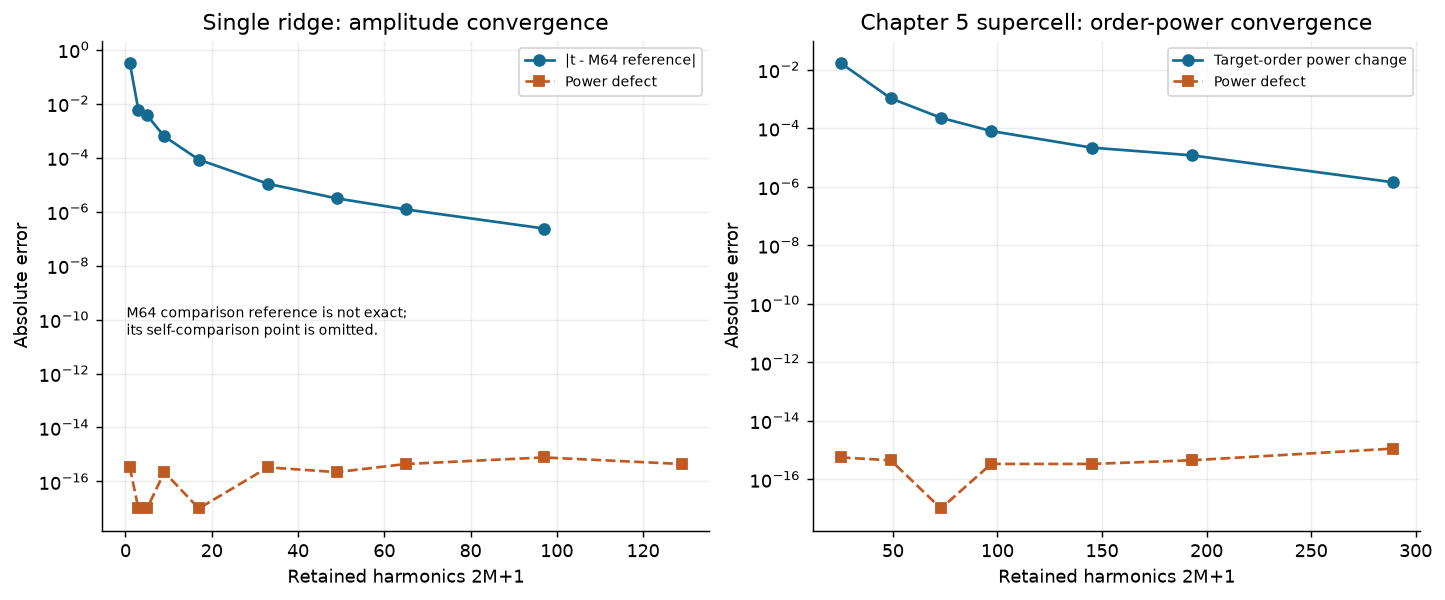

In [6]:
fixed = json.loads((ROOT/'data/chapter-06/numerical-reference.json').read_text(encoding='utf-8'))
for name,digest in fixed['metadata']['source_sha256'].items():
    assert hashlib.sha256((ROOT/'simulations'/name).read_bytes()).hexdigest()==digest, 'Rerun the Chapter 6 audit after solver changes.'
harmonics = fixed['harmonics']
supercell = json.loads((ROOT/'data/chapter-05/beam-steering.json').read_text(encoding='utf-8'))
refinements = supercell['convergence']
fig, axes = plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
axes[0].semilogy([r['retained_harmonics'] for r in harmonics[:-1]],np.maximum([r['complex_t_error'] for r in harmonics[:-1]],1e-17),'o-',color=COLORS[0],label='|t - M64 reference|')
axes[0].semilogy([r['retained_harmonics'] for r in harmonics],np.maximum([r['energy_defect'] for r in harmonics],1e-17),'s--',color=COLORS[1],label='Power defect')
axes[0].set(title='Single ridge: amplitude convergence',xlabel='Retained harmonics 2M+1',ylabel='Absolute error')
axes[1].semilogy([r['harmonics'] for r in refinements],[r['delta_target_vs_check'] for r in refinements],'o-',color=COLORS[0],label='Target-order power change')
axes[1].semilogy([r['harmonics'] for r in refinements],np.maximum([r['balance_error'] for r in refinements],1e-17),'s--',color=COLORS[1],label='Power defect')
axes[1].set(title='Chapter 5 supercell: order-power convergence',xlabel='Retained harmonics 2M+1',ylabel='Absolute error')
axes[0].text(.04,.40,'M64 comparison reference is not exact;\nits self-comparison point is omitted.',transform=axes[0].transAxes,fontsize=8)
for a in axes:a.legend(fontsize=8)
plt.show()

## 5. Preserve a reproducible decision

The cell below saves your slab experiment separately from the fixed published audit. Report a rejected coarse mesh, an accepted mesh, the tolerance, and independent domain/extraction checks. For a new physical configuration, a successful fixed-reference validator does not certify your modified experiment. The model still excludes absorption, vector patterning, finite aperture effects, and uncertain constitutive data.

Further exercises: refine FDTD run duration and absorbers independently; reproduce a Chapter 3 ridge in a converged FEM model; compare model discrepancy of a thin-sheet approximation only at matching phase planes. These are outlines, not completed simulations. Scientific methods and provenance references are recorded in `data/chapter-06/README.md` and the chapter.

In [7]:
experiment = {'parameters': asdict(SLAB), 'mesh':mesh, 'padding':padding,
              'criteria':{'complex_t':AMPLITUDE_TARGET,'phase_deg':PHASE_TARGET_DEG,'phase_amplitude_floor':PHASE_AMPLITUDE_FLOOR},
              'source_sha256':hashlib.sha256((ROOT/'simulations/numerical_methods.py').read_bytes()).hexdigest(),
              'scope':'1D lossless equal-exterior FDFD slab; RCWA figures use separate fixed datasets'}
destination = ROOT/'data/chapter-06/notebook-experiment.json'
destination.parent.mkdir(parents=True,exist_ok=True)
destination.write_text(json.dumps(experiment,indent=2,allow_nan=False)+'\n',encoding='utf-8')
print('Saved', destination.relative_to(ROOT))

Saved data\chapter-06\notebook-experiment.json
